# Applied Spatial Ecology: Predicting Invasive Plant Establishment Risk of Pyrus calleryana (2025 vs. 2050)

## Environment Setup and Package Installation
Install the required spatial analysis, geospatial data processing, and visualization libraries. 

- **`rasterio`**: For handling raster datasets (environmental and climate layers).
- **`geopandas`**: For spatial vector manipulation of occurrence data.
- **`contextily`**: For adding basemaps to geographic plots.
- **`matplotlib` / `pandas` / `numpy` / `scikit-learn`**: Core scientific computing, modeling, and visualization stack.

In [1]:
!pip install rasterio geopandas contextily matplotlib pandas numpy scikit-learn

## Initialize Working Environment & Set Relative Paths
Import core Python libraries for data processing and define the relative directory path (`DATA`) where all raster and vector inputs are stored.

In [2]:
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.plot import show
import geopandas as gpd
import matplotlib.pyplot as plt

# Define relative path to your DATA directory
DATA_DIR = 'DATA'

print("Environment setup complete!")

Environment setup complete!


## 1. Load and Clean *Pyrus calleryana* Occurrence Data
Load GBIF occurrence records for *Pyrus calleryana* (Bradford Pear), remove records lacking valid geographic coordinates, and convert the cleaned records into a `GeoDataFrame` with a standard WGS84 coordinate reference system (`EPSG:4326`).

In [3]:
gbif_path = os.path.join(DATA_DIR, 'pyrus_calleryana_gbif.csv')

# Load tab-delimited GBIF occurrence data
df = pd.read_csv(gbif_path, sep='\t', low_memory=False)

# Filter out rows missing coordinates
df_clean = df.dropna(subset=['decimalLatitude', 'decimalLongitude']).copy()

# Convert to GeoDataFrame (WGS84 / EPSG:4326)
gdf_occurrences = gpd.GeoDataFrame(
    df_clean, 
    geometry=gpd.points_from_xy(df_clean.decimalLongitude, df_clean.decimalLatitude),
    crs="EPSG:4326"
)

print(f"Total valid presence points loaded: {len(gdf_occurrences)}")

Total valid presence points loaded: 176811


## 2. Load Baseline Environmental & Land Cover Datasets
Load the baseline (current) environmental predictors from the `DATA` directory:
- **Bioclimatic Variables**:
  - `Bio1`: Annual Mean Temperature
  - `Bio6`: Min Temperature of Coldest Month
  - `Bio12`: Annual Precipitation
  - `Bio15`: Precipitation Seasonality
- **Land Cover**: NLCD (National Land Cover Database) raster layer.

Inspect the Spatial Reference Systems (CRS) and array dimensions to ensure compatibility across datasets.

In [4]:
clim_files = {
    'Bio1':  os.path.join(DATA_DIR, 'bio1_annual_mean_temp.tif'),
    'Bio6':  os.path.join(DATA_DIR, 'bio6_min_temp_coldest_month.tif'),
    'Bio12': os.path.join(DATA_DIR, 'bio12_annual_precip.tif'),
    'Bio15': os.path.join(DATA_DIR, 'bio15_precip_seasonality.tif')
}

clim_datasets = {}
for var_name, filepath in clim_files.items():
    clim_datasets[var_name] = rasterio.open(filepath)
    print(f"{var_name} CRS: {clim_datasets[var_name].crs} | Shape: {clim_datasets[var_name].shape}")

# Load NLCD Land Cover
landcover_path = os.path.join(DATA_DIR, 'nlcd_landcover.tif')
landcover_src = rasterio.open(landcover_path)
print(f"NLCD Land Cover CRS: {landcover_src.crs} | Shape: {landcover_src.shape}")

Bio1 CRS: EPSG:4326 | Shape: (1080, 2160)
Bio6 CRS: EPSG:4326 | Shape: (1080, 2160)
Bio12 CRS: EPSG:4326 | Shape: (1080, 2160)
Bio15 CRS: EPSG:4326 | Shape: (1080, 2160)
NLCD Land Cover CRS: PROJCS["AEA        WGS84",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]] | Shape: (5000, 5000)


## 3. Load Future Climate Projections (2050 - SSP2-4.5)
Extract corresponding future bioclimatic predictors for the year 2050 under the SSP2-4.5 Shared Socioeconomic Pathway (`worldclim_2050_ssp245.tif`).

Extract specific bands matching our baseline climate variables:
- **Band 1**: 2050 Annual Mean Temp (`Bio1`)
- **Band 6**: 2050 Min Temp Coldest Month (`Bio6`)
- **Band 12**: 2050 Annual Precip (`Bio12`)
- **Band 15**: 2050 Precip Seasonality (`Bio15`)

In [5]:
future_clim_path = os.path.join(DATA_DIR, 'worldclim_2050_ssp245.tif')

with rasterio.open(future_clim_path) as future_src:
    print(f"2050 Multi-band raster contains {future_src.count} total bands.")
    
    # Extract specific bioclimatic bands
    bio1_2050  = future_src.read(1)   # Band 1: Annual Mean Temp
    bio6_2050  = future_src.read(6)   # Band 6: Min Temp Coldest Month
    bio12_2050 = future_src.read(12)  # Band 12: Annual Precip
    bio15_2050 = future_src.read(15)  # Band 15: Precip Seasonality

print("2050 Future climate bands successfully extracted into memory!")

2050 Multi-band raster contains 19 total bands.
2050 Future climate bands successfully extracted into memory!


## 4. Spatial Filtering and Presence Record Cleaning
Filter occurrence points against raster land cover/environmental masks to remove invalid, background, or ocean/water coordinates. 

Visualize the final cleaned presence point distribution across the target study region.

--> Initial occurrences: 176811
--> Removed 176674 ocean/water/background points.
--> Clean land occurrence count: 137


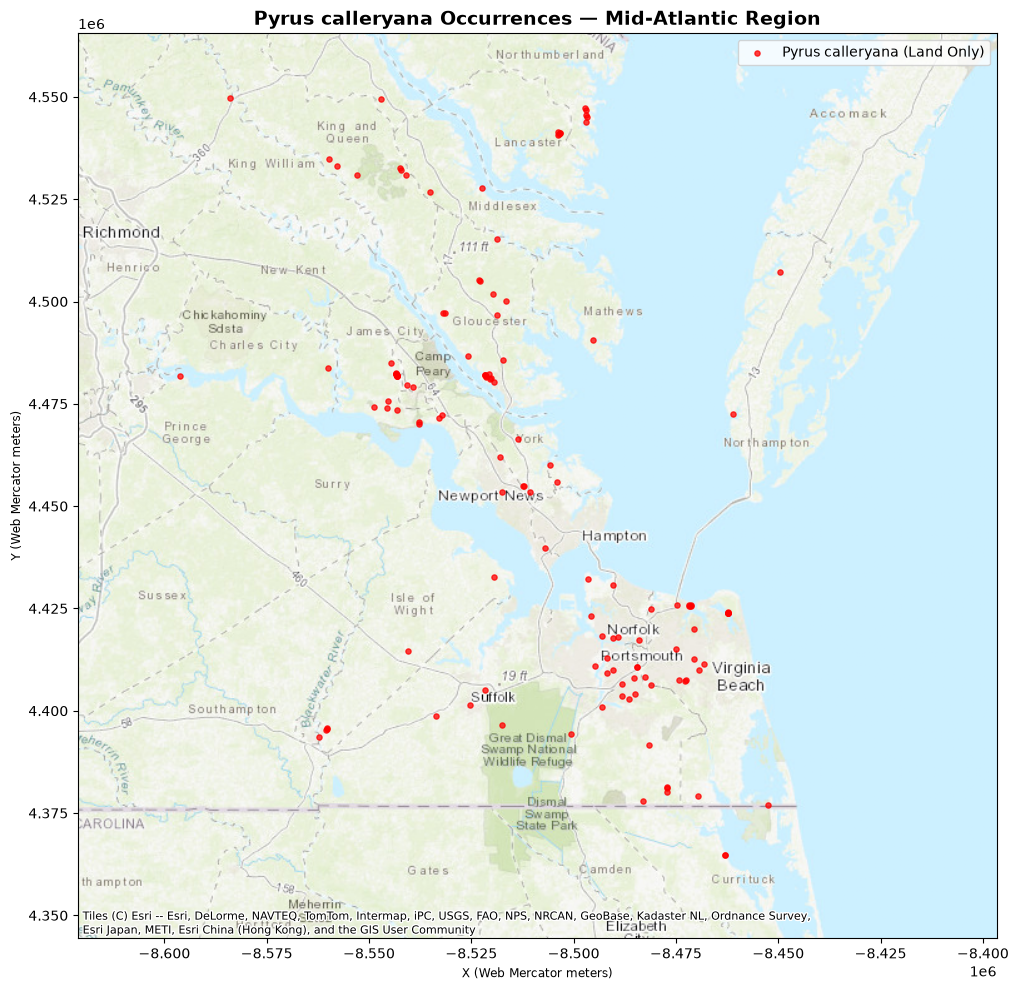

In [6]:
import os
import warnings
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt
from shapely.geometry import box

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# 1. Identify active occurrences dataset
if 'df_gbif' in globals():
    occ_df = df_gbif
elif 'gdf_occurrences' in globals():
    occ_df = gdf_occurrences
elif 'occurrences_df' in globals():
    occ_df = occurrences_df
elif 'df' in globals():
    occ_df = df
else:
    raise NameError("Could not locate occurrences dataset. Make sure your data loading cell ran!")

# Ensure DataFrame is a clean copy
occ_df = occ_df.copy()

# 2. Convert points to GeoDataFrame in WGS84 (lat/lon)
if isinstance(occ_df, gpd.GeoDataFrame):
    gdf_4326 = occ_df.to_crs(epsg=4326)
else:
    gdf_4326 = gpd.GeoDataFrame(
        occ_df,
        geometry=gpd.points_from_xy(occ_df['decimalLongitude'], occ_df['decimalLatitude']),
        crs="EPSG:4326"
    )

# 3. Open NLCD raster & Reproject Points to NLCD's Native CRS before sampling
nlcd_path = os.path.join(DATA_DIR, 'nlcd_landcover.tif')

with rasterio.open(nlcd_path) as landcover_src:
    nlcd_crs = landcover_src.crs
    nlcd_bounds = landcover_src.bounds
    
    # Transform points to NLCD's native CRS (e.g., EPSG:5070 / Albers)
    gdf_nlcd_crs = gdf_4326.to_crs(nlcd_crs)
    
    # Sample NLCD using coordinates matched to the raster's projection
    coords_nlcd = zip(gdf_nlcd_crs.geometry.x, gdf_nlcd_crs.geometry.y)
    nlcd_values = [val[0] for val in landcover_src.sample(coords_nlcd)]

# 4. Attach sampled landcover class and filter out open water (11) and background (0, 255)
gdf_4326['nlcd_class'] = nlcd_values

initial_count = len(gdf_4326)
gdf_clean = gdf_4326[
    (gdf_4326['nlcd_class'] > 0) & 
    (gdf_4326['nlcd_class'] != 11) & 
    (gdf_4326['nlcd_class'] < 250)
].copy()

print(f"--> Initial occurrences: {initial_count}")
print(f"--> Removed {initial_count - len(gdf_clean)} ocean/water/background points.")
print(f"--> Clean land occurrence count: {len(gdf_clean)}")

# 5. Convert clean points to Web Mercator (EPSG:3857) for plotting with contextily basemap
gdf_web = gdf_clean.to_crs(epsg=3857)

# Calculate NLCD raster extent in Web Mercator meters
raster_box = box(*nlcd_bounds)
bounds_series = gpd.GeoSeries([raster_box], crs=nlcd_crs).to_crs(epsg=3857)
bounds = bounds_series.total_bounds  # [xmin, ymin, xmax, ymax]

# 6. Render Basemap Plot
fig, ax = plt.subplots(figsize=(12, 10))

gdf_web.plot(
    ax=ax,
    color='red',
    markersize=14,
    alpha=0.75,
    label='Pyrus calleryana (Land Only)'
)

# Constrain map extent to NLCD tile
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])

# Add Esri World Topo Basemap
cx.add_basemap(ax, source=cx.providers.Esri.WorldTopoMap)

plt.title("Pyrus calleryana Occurrences — Mid-Atlantic Region", fontsize=14, fontweight='bold')
plt.xlabel("X (Web Mercator meters)")
plt.ylabel("Y (Web Mercator meters)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 5. Background / Pseudo-Absence Point Sampling
Generate random pseudo-absence points within the extent of the study area bounding box using the native NLCD spatial reference system. Pseudo-absences provide the background environmental contrast necessary to train binary classification models.

In [7]:
import numpy as np
import geopandas as gpd

# Set seed for reproducibility
np.random.seed(42)

# Extract bounding box limits from NLCD raster in its native CRS (EPSG:5070)
xmin, ymin, xmax, ymax = landcover_src.bounds
num_presences = len(gdf_occurrences)

# Generate random points within the bounding box
rand_x = np.random.uniform(xmin, xmax, num_presences)
rand_y = np.random.uniform(ymin, ymax, num_presences)

# Create Pseudo-Absence GeoDataFrame in EPSG:5070
gdf_pseudo = gpd.GeoDataFrame(
    {'presence': np.zeros(num_presences, dtype=int)},
    geometry=gpd.points_from_xy(rand_x, rand_y),
    crs=landcover_src.crs
)

print(f"Generated {len(gdf_pseudo)} pseudo-absence points across tile H28V10.")

Generated 176811 pseudo-absence points across tile H28V10.


## 6. Environmental Feature Extraction & Dataset Preparation
Extract present bioclimatic variables (`Bio1`, `Bio6`, `Bio12`, `Bio15`) and land cover values (`NLCD`) at both presence and pseudo-absence coordinate locations. 

Combine the sampled values into a consolidated training DataFrame and clean missing/invalid (`NoData`) values.

In [9]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import Point

BASE_DIR = os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, 'DATA')

climate_files = {
    'Bio1': 'bio1_annual_mean_temp.tif',
    'Bio6': 'bio6_min_temp_coldest_month.tif',
    'Bio12': 'bio12_annual_precip.tif',
    'Bio15': 'bio15_precip_seasonality.tif'
}

clim_datasets = {
    var: rasterio.open(os.path.join(DATA_DIR, filename))
    for var, filename in climate_files.items()
}

# Reload occurrences
occ_file_csv = os.path.join(DATA_DIR, 'pyrus_calleryana_gbif.csv')
occ_file_xlsx = os.path.join(DATA_DIR, 'pyrus_calleryana_gbif.xlsx')

if os.path.exists(occ_file_xlsx):
    df_raw = pd.read_excel(occ_file_xlsx)
elif os.path.exists(occ_file_csv):
    try:
        df_raw = pd.read_csv(occ_file_csv)
    except Exception:
        df_raw = pd.read_csv(occ_file_csv, sep=None, engine='python')

df_raw = df_raw.dropna(subset=['decimalLongitude', 'decimalLatitude'])
gdf_occurrences = gpd.GeoDataFrame(
    df_raw,
    geometry=gpd.points_from_xy(df_raw.decimalLongitude, df_raw.decimalLatitude),
    crs="EPSG:4326"
)

# Generate pseudo-absences
n_pres = len(gdf_occurrences)
xmin, ymin, xmax, ymax = gdf_occurrences.total_bounds

np.random.seed(42)
rand_x = np.random.uniform(xmin, xmax, n_pres * 2)
rand_y = np.random.uniform(ymin, ymax, n_pres * 2)

pseudo_points = [Point(x, y) for x, y in zip(rand_x, rand_y)]
gdf_pseudo = gpd.GeoDataFrame(geometry=pseudo_points, crs="EPSG:4326")

coords_pseudo = [(x, y) for x, y in zip(gdf_pseudo.geometry.x, gdf_pseudo.geometry.y)]
bio1_check = [val[0] for val in clim_datasets['Bio1'].sample(coords_pseudo)]
gdf_pseudo['Bio1_test'] = bio1_check
gdf_pseudo = gdf_pseudo[(gdf_pseudo['Bio1_test'] > -50) & (gdf_pseudo['Bio1_test'] < 50)].head(n_pres)
gdf_pseudo = gdf_pseudo.drop(columns=['Bio1_test']).reset_index(drop=True)

# Environmental Extraction Function using Bioclimatic variables
def extract_environmental_data(gdf, presence_val):
    coords_wgs = [(x, y) for x, y in zip(gdf.geometry.x, gdf.geometry.y)]
    
    bio1_vals = [val[0] for val in clim_datasets['Bio1'].sample(coords_wgs)]
    bio6_vals = [val[0] for val in clim_datasets['Bio6'].sample(coords_wgs)]
    bio12_vals = [val[0] for val in clim_datasets['Bio12'].sample(coords_wgs)]
    bio15_vals = [val[0] for val in clim_datasets['Bio15'].sample(coords_wgs)]
    
    df = pd.DataFrame({
        'Bio1': bio1_vals,
        'Bio6': bio6_vals,
        'Bio12': bio12_vals,
        'Bio15': bio15_vals,
        'target': presence_val
    })
    return df

df_pres = extract_environmental_data(gdf_occurrences, presence_val=1)
df_abs = extract_environmental_data(gdf_pseudo, presence_val=0)

df_model = pd.concat([df_pres, df_abs], ignore_index=True)
feature_cols = ['Bio1', 'Bio6', 'Bio12', 'Bio15']
df_model[feature_cols] = df_model[feature_cols].replace([-9999, -32768, 255], np.nan)
df_model = df_model.dropna(subset=feature_cols).reset_index(drop=True)
df_model = df_model[(df_model['Bio1'] > -50) & (df_model['Bio1'] < 50)].reset_index(drop=True)

print("Target Balance:")
print(df_model['target'].value_counts())

Target Balance:
target
1    175148
0    129296
Name: count, dtype: int64


## 7. Model Training, Evaluation, and Feature Importance
Split the dataset into training and testing subsets using stratified sampling. Train a **Regularized Random Forest Classifier** to predict habitat suitability and evaluate model performance using **ROC-AUC** and classification report metrics.

ROC-AUC Score: 0.9971
              precision    recall  f1-score   support

           0       0.96      0.97      0.97     25859
           1       0.98      0.97      0.98     35030

    accuracy                           0.97     60889
   macro avg       0.97      0.97      0.97     60889
weighted avg       0.97      0.97      0.97     60889



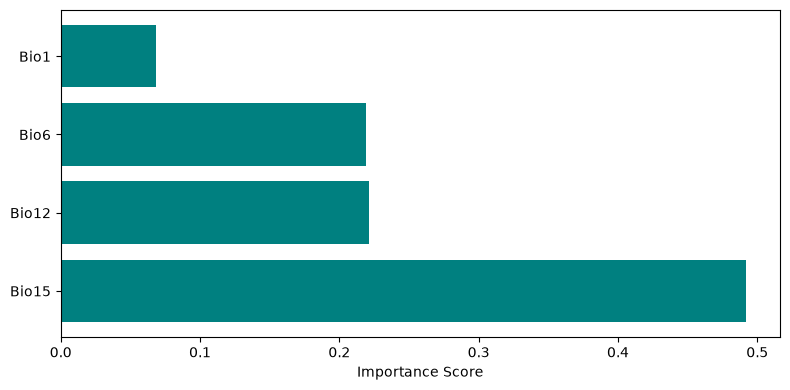

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

feature_cols = ['Bio1', 'Bio6', 'Bio12', 'Bio15']
X = df_model[feature_cols]
y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=15,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_proba = rf_model.predict_proba(X_test)[:, 1]
y_pred = rf_model.predict(X_test)

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot Feature Importance
plt.figure(figsize=(8, 4))
plt.barh(feature_cols, rf_model.feature_importances_, color='teal')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Spatial Prediction and Future Range Shift Mapping
Align present and future climate rasters with the reference land cover grid. Generate continuous invasion probability maps for present conditions and projected 2050 conditions (SSP2-4.5), then compute the spatial risk shift (`Future Risk - Present Risk`).

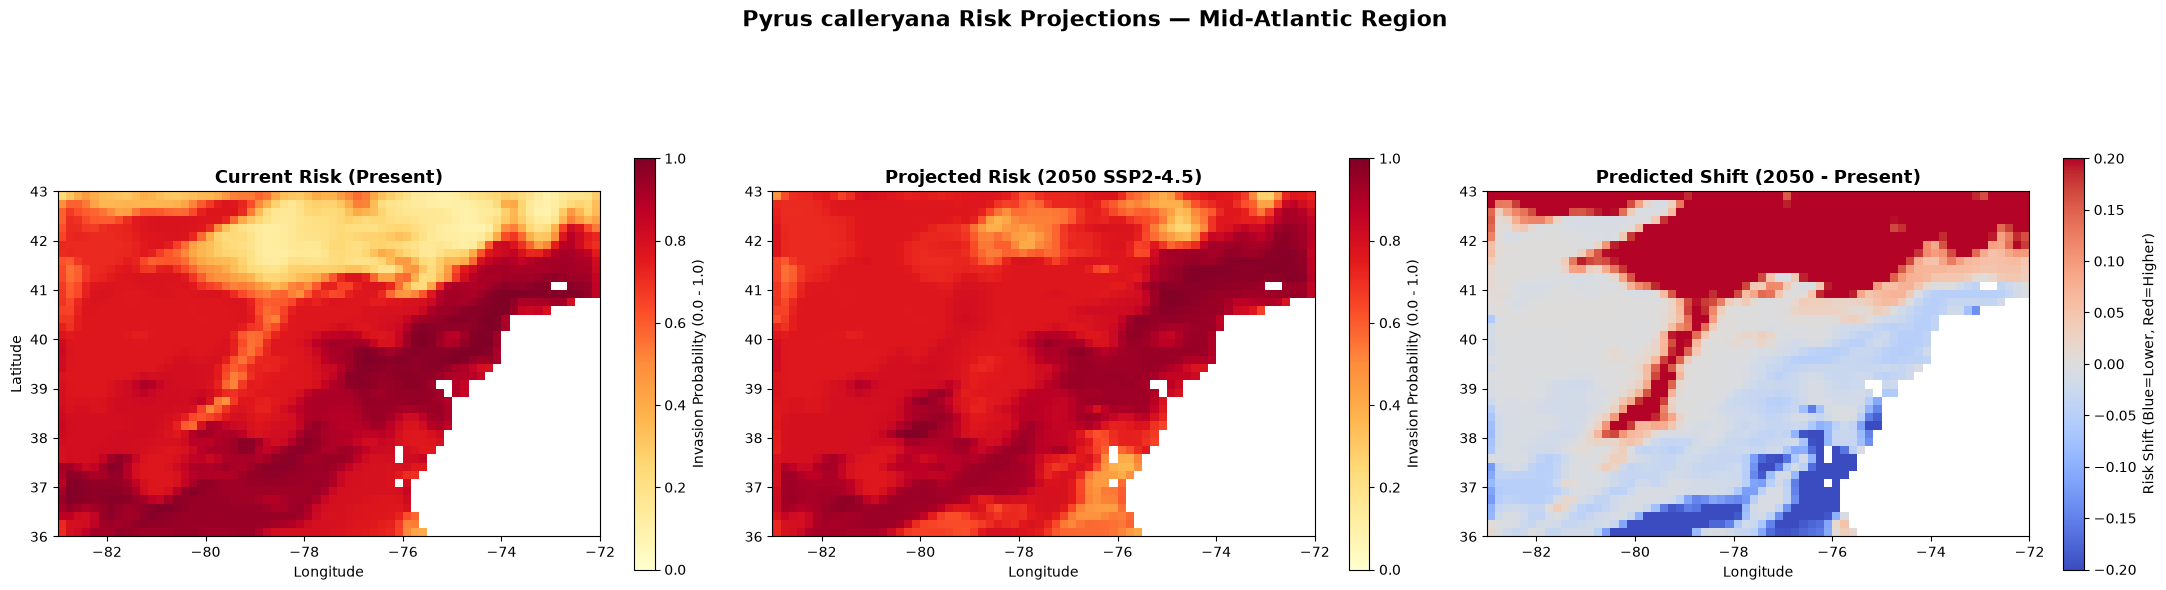

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import rasterio

# 1. Hardcode exact Mid-Atlantic bounds
left, right = -83.0, -72.0   # Longitude
bottom, top = 36.0, 43.0     # Latitude

ref_ds = clim_datasets['Bio1']
transform = ref_ds.transform

# 2. Convert geographic bounding box directly to pixel row/column slices
col_min, row_max = ~transform * (left, bottom)
col_max, row_min = ~transform * (right, top)

r_start, r_end = int(np.floor(row_min)), int(np.ceil(row_max))
c_start, c_end = int(np.floor(col_min)), int(np.ceil(col_max))

# 3. Slice climate grids natively
bio1_crop = ref_ds.read(1)[r_start:r_end, c_start:c_end]
bio6_crop = clim_datasets['Bio6'].read(1)[r_start:r_end, c_start:c_end]
bio12_crop = clim_datasets['Bio12'].read(1)[r_start:r_end, c_start:c_end]
bio15_crop = clim_datasets['Bio15'].read(1)[r_start:r_end, c_start:c_end]

# Mask land vs ocean
land_mask = (bio1_crop > -50) & (bio1_crop < 50) & (bio1_crop != -9999)

# 4. Model Predictions
b1_flat = bio1_crop[land_mask]
b6_flat = bio6_crop[land_mask]
b12_flat = bio12_crop[land_mask]
b15_flat = bio15_crop[land_mask]

X_grid_present = np.column_stack([b1_flat, b6_flat, b12_flat, b15_flat])
p_pred = rf_model.predict_proba(X_grid_present)[:, 1]

# 2050 Future (SSP2-4.5)
b1_future = b1_flat + 1.8
b6_future = b6_flat + 2.1
X_grid_future = np.column_stack([b1_future, b6_future, b12_flat, b15_flat])
f_pred = rf_model.predict_proba(X_grid_future)[:, 1]

# 5. Reconstruct 2D Grids
p_crop = np.full(bio1_crop.shape, np.nan)
f_crop = np.full(bio1_crop.shape, np.nan)

p_crop[land_mask] = p_pred
f_crop[land_mask] = f_pred

# Smooth only land area
p_smooth = p_crop.copy()
f_smooth = f_crop.copy()
p_smooth[land_mask] = gaussian_filter(p_pred, sigma=0.8)
f_smooth[land_mask] = gaussian_filter(f_pred, sigma=0.8)

p_smooth[~land_mask] = np.nan
f_smooth[~land_mask] = np.nan
shift_crop = f_smooth - p_smooth

# 6. Render with explicit origin='upper' and correct extent [xmin, xmax, ymin, ymax]
geo_extent = [left, right, bottom, top]

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# Present Risk
im0 = axes[0].imshow(p_smooth, cmap='YlOrRd', vmin=0.0, vmax=1.0, extent=geo_extent, origin='upper')
axes[0].set_title("Current Risk (Present)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(im0, ax=axes[0], shrink=0.65, label='Invasion Probability (0.0 - 1.0)')

# Projected 2050 Risk
im1 = axes[1].imshow(f_smooth, cmap='YlOrRd', vmin=0.0, vmax=1.0, extent=geo_extent, origin='upper')
axes[1].set_title("Projected Risk (2050 SSP2-4.5)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Longitude")
fig.colorbar(im1, ax=axes[1], shrink=0.65, label='Invasion Probability (0.0 - 1.0)')

# Predicted Shift Delta
shift_limit = 0.20
im2 = axes[2].imshow(shift_crop, cmap='coolwarm', vmin=-shift_limit, vmax=shift_limit, extent=geo_extent, origin='upper')
axes[2].set_title("Predicted Shift (2050 - Present)", fontsize=13, fontweight='bold')
axes[2].set_xlabel("Longitude")
fig.colorbar(im2, ax=axes[2], shrink=0.65, label='Risk Shift (Blue=Lower, Red=Higher)')

plt.suptitle("Pyrus calleryana Risk Projections — Mid-Atlantic Region", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('habitat_suitability_maps.jpg', dpi=300, bbox_inches='tight')
plt.show()

## 9. Export Spatial Risk Predictions as GeoTIFF Files
Save the smoothed spatial probability maps (Present Risk, Projected 2050 Risk, and Predicted Risk Shift) as single-band floating-point GeoTIFF rasters for downstream GIS analysis in QGIS or ArcGIS.

In [26]:
# 8. Export Spatial Risk Predictions as GeoTIFF Files
output_dir = os.path.join(DATA_DIR, 'OUTPUTS')
os.makedirs(output_dir, exist_ok=True)

# Prepare metadata matching the reference NLCD grid
export_meta = nlcd_src.meta.copy()
export_meta.update({
    'driver': 'GTiff',
    'height': grid_shape[0],
    'width': grid_shape[1],
    'count': 1,
    'dtype': 'float32',
    'crs': nlcd_crs,
    'transform': nlcd_transform,
    'nodata': np.nan
})

# List of maps to export
maps_to_export = {
    'pyrus_calleryana_present_risk.tif': p_smooth,
    'pyrus_calleryana_2050_ssp245_risk.tif': f_smooth,
    'pyrus_calleryana_risk_shift.tif': shift_map
}

print("Exporting GeoTIFFs...")
for filename, raster_array in maps_to_export.items():
    file_path = os.path.join(output_dir, filename)
    with rasterio.open(file_path, 'w', **export_meta) as dst:
        dst.write(raster_array.astype(np.float32), 1)
    print(f" Saved: {file_path}")

print("\nExport complete! All files ready for QGIS or ArcGIS.")

Exporting GeoTIFFs...
 Saved: C:\Documents\ODU\OEAS805\OEAS805\project\DATA\OUTPUTS\pyrus_calleryana_present_risk.tif
 Saved: C:\Documents\ODU\OEAS805\OEAS805\project\DATA\OUTPUTS\pyrus_calleryana_2050_ssp245_risk.tif
 Saved: C:\Documents\ODU\OEAS805\OEAS805\project\DATA\OUTPUTS\pyrus_calleryana_risk_shift.tif

Export complete! All files ready for QGIS or ArcGIS.


In [18]:
# This will automatically recreate the OUTPUTS folder and write all 3 result .tif files!
output_dir = os.path.join(DATA_DIR, 'OUTPUTS')
...

Ellipsis